# Device selection

In [1]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"
device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_57990/3737875437.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

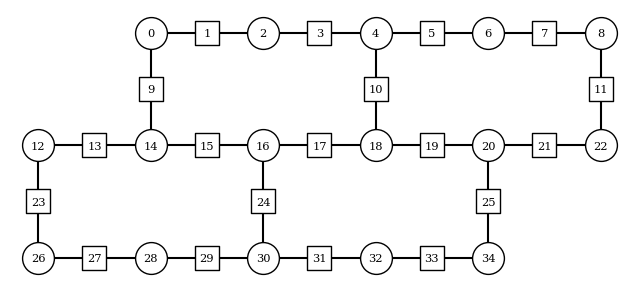

In [2]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 2
plaquette_height = 2

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
lattice.plot_lattice(number_qubits=True)

# Simulation settings

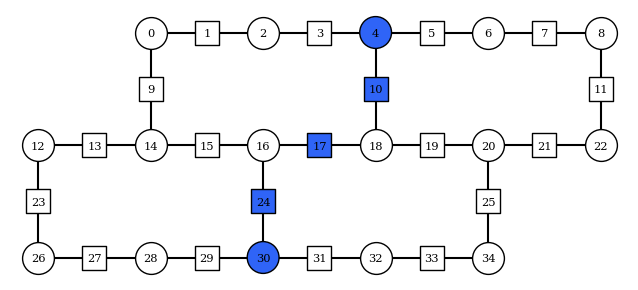

In [3]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 2
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 59]
string = [4, 10, 17, 24, 30]
# string = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]

final_time = 3
dt = 0.15
steps = 20
desired_error = 1e-2

confidence = 0.9

cal = True
postselect_odr = True
flip_threshold = 2
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

pt_num_randomizations = 60
pt_shots_per_randomization = 5000

shots = pt_num_randomizations * pt_shots_per_randomization
max_shots = 100000
# shots = 75000
# max_shots = 75000

final_twirl_randomizations = pt_num_randomizations
if shots > max_shots:
    final_twirl_randomizations = int(final_twirl_randomizations * max_shots / shots)
if all_or_first_layout_qubit == True:
    final_twirl_randomizations = int(final_twirl_randomizations/max_layouts)
# if final_twirl_randomizations < 1:
#     final_twirl_randomizations = 1

# sampler_options = {
#     "default_shots": shots,
#     "execution": {
#         "init_qubits": True,
#         "meas_type": "classified"
#     },
#     "dynamical_decoupling": {
#         "enable": False,
#         "sequence_type": "XY4"
#     },
#     "twirling": {
#         "enable_gates": True,
#         "enable_measure": True,
#         "num_randomizations": final_twirl_randomizations,
#         "shots_per_randomization": pt_shots_per_randomization
#     }
# }

shots = 75000

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs_preshutdown.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True, filepath="z2hex_quench_initial_state.png")

# Load data

In [4]:
# from utils.postselection_multithreaded import load_postselected_jobs_obs
# import pickle
# import os

# curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")

# with open(curated_data_filepath, "rb") as f:
#     hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

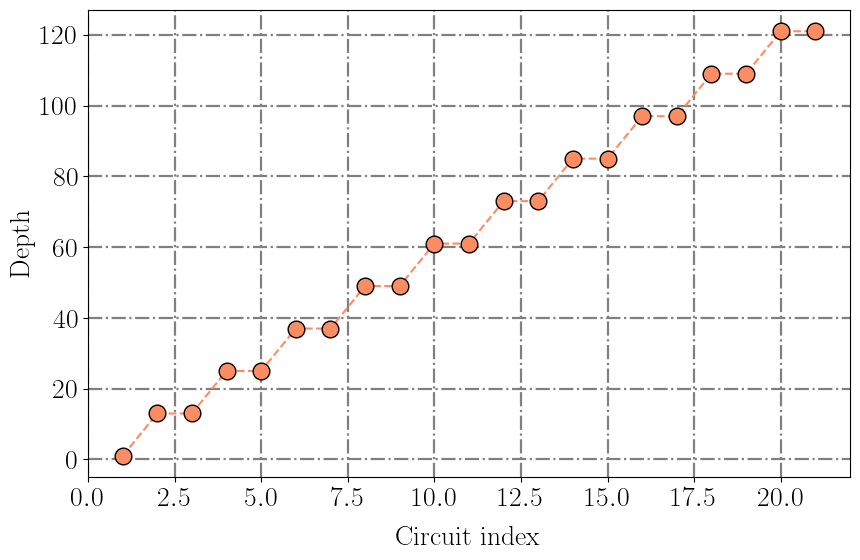

In [5]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, get_layouts
from z2hex.geometry import HeavyHexLattice, sort_layouts_by_func, measurement_decoherence_layout_cost
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3
barriers = False

lattice = HeavyHexLattice(*lattice_dims)

if all_or_first_layout_qubit == True:
    all_layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
    layouts = sort_layouts_by_func(all_layouts, lambda x: measurement_decoherence_layout_cost(x, backend))[:max_layouts]
elif isinstance(all_or_first_layout_qubit, int):
    layouts = [lattice.initial_qubit_layout(first_qubit=all_or_first_layout_qubit, backend=device)]
else:
    layouts = None
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, barriers)
# "max_shots" option was not present before changing PT
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis} | ({"fractional_gates": True} if fractional_gates else {})
if cal:
    circuits, odr_circuits = simulation_and_odr_circuits(*circs_args)
else:
    circuits = simulation_and_odr_circuits(*circs_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_circuit_arr_depth(circuits[0])

In [6]:
from utils.postselection_multithreaded import load_postselected_jobs_obs, load_postselected_jobs_inverse_order
import pickle
import os

job_index = 0
minimum_shots = 5000

overwrite = False
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_dd_{sampler_options["dynamical_decoupling"]["enable"]}_pt_{sampler_options["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
else:
    curated_data_filepath = ""

if overwrite or not os.path.exists(curated_data_filepath):
    if cal:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, job_index=job_index, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True, max_shots=max_shots, minimum_shots=minimum_shots)
    else:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs_obs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, job_index=job_index, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True, max_shots=max_shots, minimmum_shots=minimum_shots)
    if curated_data_filepath is not None:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

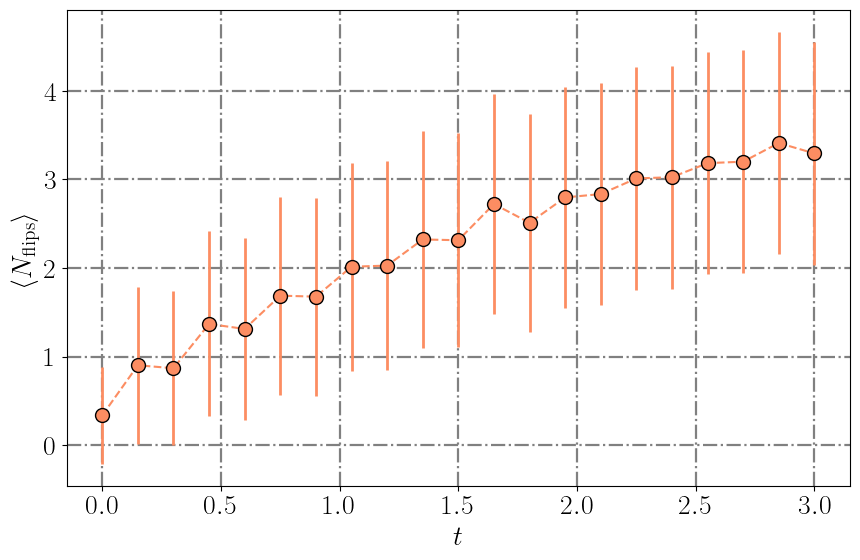

In [7]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
import matplotlib.pyplot as plt
from pymatching import Matching

plot_filepath = f"z2hex_quench_nflips_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
decoder = Matching(postselection_mask)

distribution_means = np.zeros(steps+1)
standard_distributions = np.zeros(steps+1)
for i in range(steps+1):
    all_layouts_samples_dicts = [samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
    if combined_samples_dict == {}:
        distribution_means[i] = np.nan
        standard_distributions[i] = np.nan
    else:
        states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
        state_counts = np.array(list(combined_samples_dict.values()))
        states_syndromes = (states @ postselection_mask.T) % 2
        predicted_flips = decoder.decode_batch(states_syndromes)
        nflips = predicted_flips.sum(axis=1)
        unique_nflips = np.unique(nflips)
        this_flip_counts = {}
        this_total_nflips = 0
        for nf in unique_nflips:
            this_counts = np.sum(state_counts[np.equal(nflips, nf)])
            this_flip_counts[nf] = this_counts
            this_total_nflips += this_counts
        this_mean = 0
        for nf, counts in this_flip_counts.items():
            this_mean += nf*counts/this_total_nflips
        distribution_means[i] = this_mean
        for nf, counts in this_flip_counts.items():
            standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
        standard_distributions[i] = np.sqrt(standard_distributions[i])

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])

x = np.linspace(0, final_time, steps+1)
x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

plt.errorbar(x, distribution_means, yerr=standard_distributions, fmt="o--", color=plt.get_cmap("Set2")(1), markersize=10, elinewidth=2, markeredgecolor="black")
plt.xlabel(r"$t$")
plt.ylabel(r"$\langle N_{\mathrm{flips}} \rangle$")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.tight_layout()
# plt.savefig(plot_filepath)
plt.rcdefaults()

# With number operator

In [8]:
from utils.plotting import plot_individual_qubits_observable_evolution
from utils.observables import load_projection_operators
import matplotlib.pyplot as plt
import numpy as np

# J = 5
# h = 2
# lamb = 1

# string = [4, 10, 17, 24, 30]

# final_time = 3
# dt = 0.175

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]
# string_qubits = [
#     [2, 16, 22, 26],
#     [2, 16, 26, 32]
# ]
string_qubits = [
    [4, 30],
    [14, 20]
]

labels = [
    "-".join([str(i) for i in st]) for st in string_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = None # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = False

occupation_operators_vals, occupation_operators_confidence = load_projection_operators(samples_dicts_to_plot, string_qubits, cal_samples_dicts=samples_dicts_to_cal, confidence=0.9, shots=shots)

plot_filepath = f"z2hex_quench_occupation_correlators_{"-".join(labels)}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

qubits = [x for xs in string_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(string_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=None, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--")
lattice.plot_highlighted_qubits(qubits, colors=colors)

ImportError: cannot import name 'load_projection_operators' from 'utils.observables' (/Users/cobos/MEGAsync/Doctorado/2nd year/IBM hardware execution/Repo/src/utils/observables.py)

# As sum of Pauli correlators

In [ ]:
from utils.postselection_multithreaded import measure_diagonal_observables
from z2chain.operators import pauli_z_tensor
from multiprocessing import Pool, cpu_count
from itertools import product, combinations
import utils.odr as odr

def load_single_occupation_correlators_paulis(samples_dict, occupied_qubits, cal_samples_dict=None, confidence=None, shots=None):
    # Generate the pauli observable list involved in the correlator
    nqubits = len(list(samples_dict.keys())[0])
    pauli_zs = []
    signs = []
    for i in range(1, len(occupied_qubits)+1):
        these_pauli_zs = []
        for comb in combinations(occupied_qubits, i):
            these_pauli_zs.append(pauli_z_tensor(nqubits, comb))
        signs += [(-1)**i]*len(these_pauli_zs)
        pauli_zs += these_pauli_zs
    if confidence is not None:
        evals, evals_confidence = measure_diagonal_observables(samples_dict, pauli_zs, confidence=confidence)
        if cal_samples_dict is not None:
            cal_evals, cal_evals_confidence = measure_diagonal_observables(cal_samples_dict, pauli_zs, confidence=confidence)
            return (evals, cal_evals), (evals_confidence, cal_evals_confidence), signs
        else:
            return evals, evals_confidence, signs
    else:
        evals = measure_diagonal_observables(samples_dict, pauli_zs)
        if cal_samples_dict is not None:
            cal_evals = measure_diagonal_observables(cal_samples_dict, pauli_zs)
            return (evals, cal_evals), signs
        else:
            return evals, signs
    
def _paulis_results_to_occ_corrs(results, occupied_qubits):
    confidence_present = (len(results[0]) == 3) and isinstance(results[0][0], tuple)
    cal_present = isinstance(results[0][0], tuple)

    occ_qb_paulisz_evals = []
    occ_qb_paulisz_signs = []
    if confidence_present:
        occ_qb_paulisz_confidence = []
        if cal_present:
            cal_occ_qb_paulisz_evals = []
            cal_occ_qb_paulisz_confidence = []
            for result in results:
                occ_qb_paulisz_evals.append(result[0][0])
                cal_occ_qb_paulisz_evals.append(result[0][1])
                occ_qb_paulisz_confidence.append(result[1][0])
                cal_occ_qb_paulisz_confidence.append(result[1][1])
                occ_qb_paulisz_signs.append(result[-1])
        else:
            for result in results:
                occ_qb_paulisz_evals.append(result[0])
                occ_qb_paulisz_confidence.append(result[1])
                occ_qb_paulisz_signs.append(result[-1])
    else:
        if cal_present:
            cal_occ_qb_paulisz_evals = []
            for result in results:
                occ_qb_paulisz_evals.append(result[0][0])
                cal_occ_qb_paulisz_evals.append(result[0][1])
                occ_qb_paulisz_signs.append(result[-1])
        else:
            for result in results:
                occ_qb_paulisz_evals.append(result[0])
                occ_qb_paulisz_signs.append(result[-1])

    nsamples_dicts = len(occ_qb_paulisz_evals)//len(occupied_qubits)
    occupation_correlators_evals = np.zeros((nsamples_dicts, len(occupied_qubits)))
    if cal_present:
        cal_occupation_correlators_evals = np.zeros((nsamples_dicts, len(occupied_qubits)))
        corrected_occupation_correlators_evals = np.zeros((nsamples_dicts, len(occupied_qubits)))
    if confidence_present:
        occupation_correlators_confidence = np.zeros((nsamples_dicts, len(occupied_qubits), 2))
        if cal_present:
            cal_occupation_correlators_confidence = np.zeros((nsamples_dicts, len(occupied_qubits), 2))
            corrected_occupation_correlators_confidence = np.zeros((nsamples_dicts, len(occupied_qubits), 2))
    for i, occ_qb in enumerate(occupied_qubits):
        this_occ_qb_paulisz_evals = np.array(occ_qb_paulisz_evals[i*nsamples_dicts:(i+1)*nsamples_dicts])
        this_occ_qb_paulisz_signs = np.array(occ_qb_paulisz_signs[i*nsamples_dicts:(i+1)*nsamples_dicts])
        occupation_correlators_evals[:, i] = (1 + np.sum(this_occ_qb_paulisz_evals * this_occ_qb_paulisz_signs, axis=1))/2**len(occ_qb)
        if cal_present:
            this_cal_occ_qb_paulisz_evals = np.array(cal_occ_qb_paulisz_evals[i*nsamples_dicts:(i+1)*nsamples_dicts])
            cal_occupation_correlators_evals[:, i] = (1 + np.sum(this_cal_occ_qb_paulisz_evals * this_occ_qb_paulisz_signs, axis=1))/2**len(occ_qb)
            corrected_pauliz_evals = np.zeros_like(this_occ_qb_paulisz_evals)
            if confidence_present:
                this_occ_qb_paulisz_confidence = np.array(occ_qb_paulisz_confidence[i*nsamples_dicts:(i+1)*nsamples_dicts])
                corrected_pauliz_confidence = np.zeros_like(this_occ_qb_paulisz_confidence)
            for j in range(this_cal_occ_qb_paulisz_evals.shape[1]):
                p_arr = odr.compute_depolarizing_probability(this_cal_occ_qb_paulisz_evals[:, j], 1, 0, 0)
                if confidence_present:
                    corrected_pauliz_evals[:, j], corrected_pauliz_confidence[:, j, :] = odr.renormalize_observable(this_occ_qb_paulisz_evals[:, j], p_arr, 0, 0, observable_range=[-1, 1], expected_observable_arr=1, observable_confidence=this_occ_qb_paulisz_confidence[:, j, :])
                else:
                    corrected_pauliz_evals[:, j] = odr.renormalize_observable(this_occ_qb_paulisz_evals[:, j], p_arr, 0, 0, observable_range=[-1, 1], expected_observable_arr=1)
            corrected_occupation_correlators_evals[:, i] = (1 + np.sum(corrected_pauliz_evals * this_occ_qb_paulisz_signs, axis=1))/2**len(occ_qb)
        if confidence_present:
            confidence_deltas = np.abs(this_occ_qb_paulisz_confidence - this_occ_qb_paulisz_evals.reshape((*this_occ_qb_paulisz_confidence.shape[:2], 1)))
            confidence_deltas = np.abs(np.sum(confidence_deltas * this_occ_qb_paulisz_signs.reshape((*this_occ_qb_paulisz_confidence.shape[:2], 1)), axis=1)/2**len(occ_qb))
            occupation_correlators_confidence[:, i, 0] = occupation_correlators_evals[:, i] - confidence_deltas[:, 0]
            occupation_correlators_confidence[:, i, 1] = occupation_correlators_evals[:, i] + confidence_deltas[:, 1]
            if cal_present:
                this_cal_occ_qb_paulisz_confidence = np.array(cal_occ_qb_paulisz_confidence[i*nsamples_dicts:(i+1)*nsamples_dicts])
                cal_confidence_deltas = np.abs(this_cal_occ_qb_paulisz_confidence - this_cal_occ_qb_paulisz_evals.reshape((*this_cal_occ_qb_paulisz_confidence.shape[:2], 1)))
                cal_confidence_deltas = np.abs(np.sum(cal_confidence_deltas * this_occ_qb_paulisz_signs.reshape((*this_occ_qb_paulisz_confidence.shape[:2], 1)), axis=1)/2**len(occ_qb))
                cal_occupation_correlators_confidence[:, i, 0] = cal_occupation_correlators_evals[:, i] - cal_confidence_deltas[:, 0]
                cal_occupation_correlators_confidence[:, i, 1] = cal_occupation_correlators_evals[:, i] + cal_confidence_deltas[:, 1]
                corrected_confidence_deltas = np.abs(corrected_pauliz_confidence - corrected_pauliz_evals.reshape((*corrected_pauliz_confidence.shape[:2], 1)))
                corrected_confidence_deltas = np.abs(np.sum(corrected_confidence_deltas * this_occ_qb_paulisz_signs.reshape((*corrected_pauliz_confidence.shape[:2], 1)), axis=1)/2**len(occ_qb))
                corrected_occupation_correlators_confidence[:, i, 0] = corrected_occupation_correlators_evals[:, i] - corrected_confidence_deltas[:, 0]
                corrected_occupation_correlators_confidence[:, i, 1] = corrected_occupation_correlators_evals[:, i] + corrected_confidence_deltas[:, 1]
    
    if cal_present:
        to_return = [corrected_occupation_correlators_evals, occupation_correlators_evals, cal_occupation_correlators_evals]
    else:
        to_return = [occupation_correlators_evals]
    if confidence_present:
        if cal_present:
            to_return = (to_return, [corrected_occupation_correlators_confidence, occupation_correlators_confidence, cal_occupation_correlators_confidence])
        else:
            to_return.append(occupation_correlators_confidence)
    return to_return

def load_occupation_correlators_bypaulis(samples_dicts, occupied_qubits, cal_samples_dicts=None, confidence=None, shots=None):
    if isinstance(samples_dicts, dict):
        samples_dicts = [samples_dicts]
    elif not isinstance(samples_dicts, (list, tuple, np.ndarray)):
        raise ValueError("samples_dicts must be a list, tuple, or numpy array")
    samples_dicts = np.array(samples_dicts, dtype=object)
    if isinstance(occupied_qubits[0], int):
        occupied_qubits = [occupied_qubits]
    elif not isinstance(occupied_qubits, (list, tuple, np.ndarray)):
        raise ValueError("occupied_qubits must be list of list of indices")
    if len(samples_dicts.shape) != 1:
        raise ValueError("samples_dicts must be a 1D array of dictionaries")
    if cal_samples_dicts is not None:
        cal_samples_dicts = np.array(cal_samples_dicts, dtype=object)
        if cal_samples_dicts.shape != samples_dicts.shape:
            raise ValueError("cal_samples_dicts must have the same shape as samples_dicts")

    results = []
    for i, occ_qbs in enumerate(occupied_qubits):
        for j, samples_dict in enumerate(samples_dicts):
            results.append(load_single_occupation_correlators_paulis(samples_dict, occ_qbs, cal_samples_dict=cal_samples_dicts[j] if cal_samples_dicts is not None else None, confidence=confidence, shots=shots))

    return _paulis_results_to_occ_corrs(results, occupied_qubits)

In [ ]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

samples_dicts_to_plot = postselected_samples_dicts[0][0]
samples_dicts_to_cal = postselected_samples_dicts[1][0]
# string_qubits = [
#     [2, 16, 22, 26],
#     [2, 16, 26, 32]
# ]
occupied_qubits = [
    [4, 30],
    [14, 20]
]

labels = [
    "-".join([str(i) for i in st]) for st in occupied_qubits
]

cmap = plt.get_cmap("Set2")
x_ticks = np.linspace(0, final_time, 6)
x_label = r"$t$"
y_label = r"String correlators"
y_lim = None # "data" for data limits, None for auto, [,] for custom
title = f"$m = {J:.02f}$ / $g = {h:.02f}$ / $dt = {dt:.03f}$"
legend = False

# occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(postselected_samples_dicts[0][0], occupied_qubits, samples_dicts_to_cal, 0.9, None)
occupation_operators_vals, occupation_operators_confidence = load_occupation_correlators_bypaulis(postselected_samples_dicts[0][0], occupied_qubits, samples_dicts_to_cal, 0.9, None)

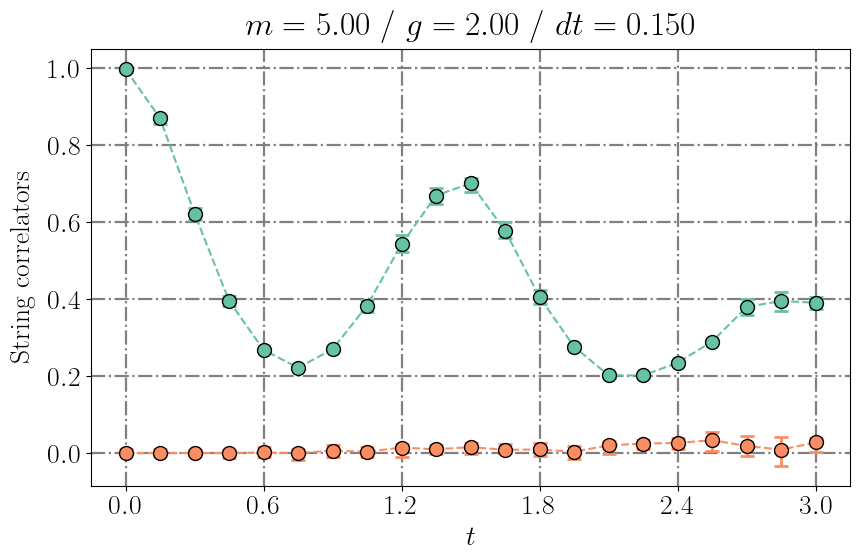

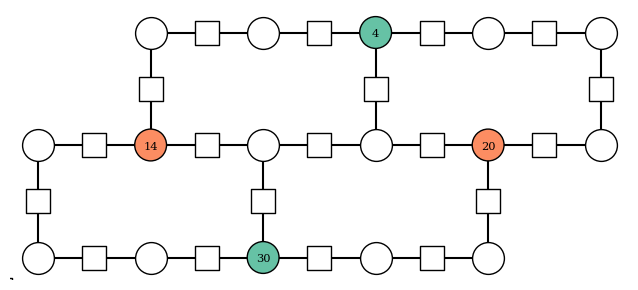

In [ ]:
qubits = [x for xs in occupied_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(occupied_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[0]
observables_stdm = occupation_operators_confidence[0]

plot_filepath = f"z2hex_quench_occupation_correlators_{"-".join(labels)}_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--", plot_filepath=plot_filepath)
lattice.plot_highlighted_qubits(qubits, colors=colors)

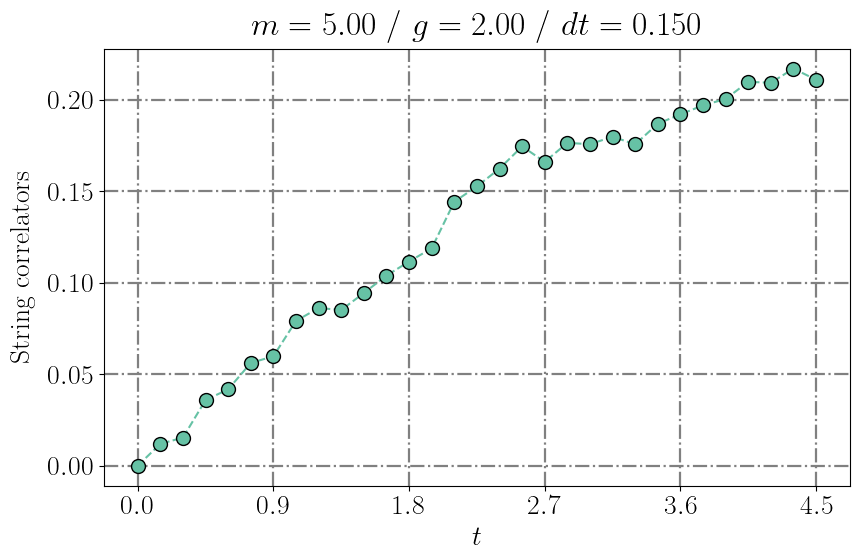

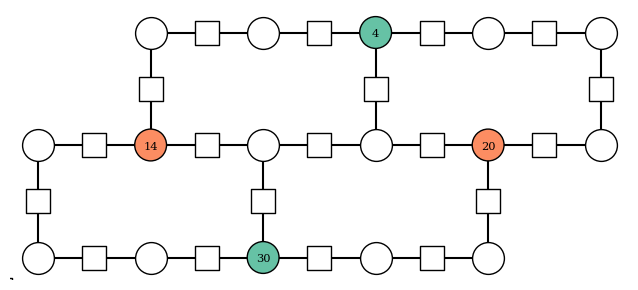

In [ ]:
qubits = [x for xs in string_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(string_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[1]
# observables_stdm = occupation_operators_confidence[0]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--")
lattice.plot_highlighted_qubits(qubits, colors=colors)

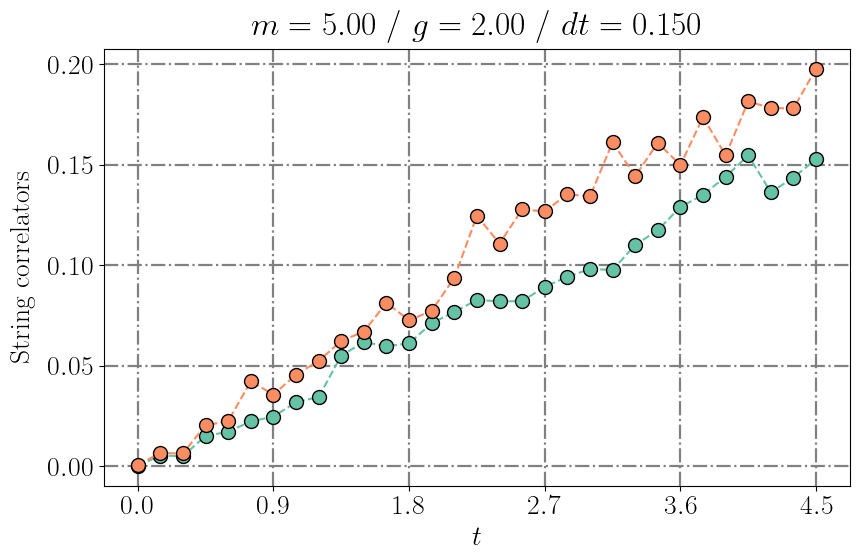

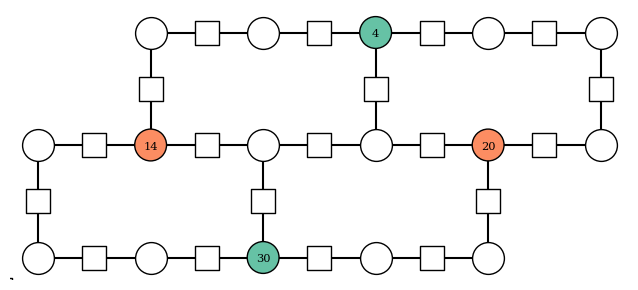

In [ ]:
qubits = [x for xs in string_qubits for x in xs]
to_plot_string_qubits = list(set(string) - set(qubits))
colors = []
for i, s in enumerate(string_qubits):
    colors += [cmap(i%8)]*len(s)
colors += ["#2f64f7"]*len(to_plot_string_qubits)

observables_to_plot = occupation_operators_vals[2]
# observables_stdm = occupation_operators_confidence[0]

plot_individual_qubits_observable_evolution(observables_to_plot, observable_confidence_matrix=observables_stdm, function_over=None, ylabel=y_label, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=y_lim, title=title, legend=legend, fmt="o--")
lattice.plot_highlighted_qubits(qubits, colors=colors)

In [ ]:
occupation_operators_vals

[array([[-2.16101628e-05],
        [ 1.14025429e-03],
        [ 2.89008298e-03],
        [ 3.53587079e-03],
        [ 6.08708930e-03],
        [ 3.60524731e-03],
        [ 5.93794555e-03],
        [ 1.26185985e-02],
        [ 1.37182108e-02],
        [ 6.46806828e-03],
        [ 1.00188453e-02],
        [ 4.76061111e-03],
        [ 1.73707259e-02],
        [ 1.89420648e-02],
        [ 3.19156343e-02],
        [ 1.87897151e-02],
        [ 4.00153919e-02],
        [ 3.35511471e-02],
        [ 1.27265874e-02],
        [ 2.50933448e-02],
        [ 5.02433484e-02],
        [-3.20374967e-02],
        [-9.15964655e-03],
        [-1.14313662e-02],
        [ 7.22597649e-02],
        [-4.26534198e-03],
        [ 4.25310760e-02],
        [-1.55176320e-02],
        [ 7.24433296e-02],
        [ 1.10118770e-01],
        [-5.35898383e-02]]),
 array([[1.00034012e-05],
        [1.19160365e-02],
        [1.53476526e-02],
        [3.58479789e-02],
        [4.17537332e-02],
        [5.61414930e-02],
     